In [1]:
import requests
import pandas as pd
from datetime import date

url = "https://restcountries.com/v3.1/all?fields=name,population,region"

response = requests.get(url, timeout=30)
response.raise_for_status()

countries = response.json()

print("取得日：", date.today())
print("取得した国・地域の数：", len(countries))

ModuleNotFoundError: No module named 'pandas'

In [2]:
import requests
import pandas as pd
from datetime import date

url = "https://restcountries.com/v3.1/all?fields=name,population,region"

response = requests.get(url, timeout=30)
response.raise_for_status()

countries = response.json()

print("取得日：", date.today())
print("取得した国・地域の数：", len(countries))

取得日： 2026-10-21
取得した国・地域の数： 3


In [3]:
import requests

url = "https://restcountries.com/v3.1/all?fields=name%2Cpopulation%2Cregion"

response = requests.get(url, timeout=30)

print("ステータスコード：", response.status_code)
print("データ形式：", response.headers.get("Content-Type"))
print("取得結果の最初の300文字：")
print(response.text[:300])

ステータスコード： 200
データ形式： application/json
取得結果の最初の300文字：
{
    "success": false,
    "data": null,
    "errors": [
        {
            "message": "This API version has been deprecated. Please visit https://restcountries.com/docs/countries/legacy-api-deprecation to migrate to our new version (v5)."
        }
    ]
}


In [4]:
url = "https://api.restcountries.com/countries/v5"

In [5]:
import requests

url = "https://api.restcountries.com/countries/v5"

headers = {
    "Authorization": "Bearer rc_live_demo"
}

params = {
    "response_fields": "names.common,population,region",
    "limit": 3
}

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

print("ステータスコード：", response.status_code)

result = response.json()
print(result)

ステータスコード： 200
{'data': {'_demo': {'message': 'You just ran a test against the demo key. To get real data, sign up for an API key here: https://restcountries.com/sign-up. Below is one example object showing the response shape you would get back from a real query.', 'signup_url': 'https://restcountries.com/sign-up'}, 'objects': [{'names': {'alternates': [], 'common': 'Canada', 'native': {'eng': {'common': 'Canada', 'official': 'Canada'}, 'fra': {'common': 'Canada', 'official': 'Canada'}}, 'official': 'Canada', 'translations': {'ara': {'common': 'كندا', 'official': 'كندا'}, 'bre': {'common': 'Kanada', 'official': 'Kanada'}, 'ces': {'common': 'Kanada', 'official': 'Kanada'}, 'cym': {'common': 'Canada', 'official': 'Canada'}, 'deu': {'common': 'Kanada', 'official': 'Kanada'}, 'est': {'common': 'Kanada', 'official': 'Kanada'}, 'fas': {'common': 'کانادا', 'official': 'کانادا'}, 'fin': {'common': 'Kanada', 'official': 'Kanada'}, 'fra': {'common': 'Canada', 'official': 'Canada'}, 'hrv': {'commo

In [6]:
import pandas as pd

# APIから取得したデータを確認
print(type(result))
print(result.keys() if isinstance(result, dict) else "リスト形式です")

<class 'dict'>
dict_keys(['data'])


In [7]:
# dataの中身を確認する
data = result["data"]

print("データの種類：", type(data))
print("データの数：", len(data))
print("最初のデータ：", data[0] if isinstance(data, list) and len(data) > 0 else data)

データの種類： <class 'dict'>
データの数： 3
最初のデータ： {'_demo': {'message': 'You just ran a test against the demo key. To get real data, sign up for an API key here: https://restcountries.com/sign-up. Below is one example object showing the response shape you would get back from a real query.', 'signup_url': 'https://restcountries.com/sign-up'}, 'objects': [{'names': {'alternates': [], 'common': 'Canada', 'native': {'eng': {'common': 'Canada', 'official': 'Canada'}, 'fra': {'common': 'Canada', 'official': 'Canada'}}, 'official': 'Canada', 'translations': {'ara': {'common': 'كندا', 'official': 'كندا'}, 'bre': {'common': 'Kanada', 'official': 'Kanada'}, 'ces': {'common': 'Kanada', 'official': 'Kanada'}, 'cym': {'common': 'Canada', 'official': 'Canada'}, 'deu': {'common': 'Kanada', 'official': 'Kanada'}, 'est': {'common': 'Kanada', 'official': 'Kanada'}, 'fas': {'common': 'کانادا', 'official': 'کانادا'}, 'fin': {'common': 'Kanada', 'official': 'Kanada'}, 'fra': {'common': 'Canada', 'official': 'Canada'

In [8]:
import requests
import pandas as pd

# 世界銀行から最新の人口データを取得
url = "https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&mrv=1&per_page=400"

response = requests.get(url, timeout=30)
response.raise_for_status()

result = response.json()

print("取得したデータの形式：", type(result))
print("取得した国・地域の数：", len(result[1]))
print("最初のデータ：", result[1][0])

取得したデータの形式： <class 'list'>
取得した国・地域の数： 400
最初のデータ： {'indicator': {'id': 'SP.POP.TOTL', 'value': 'Population, total'}, 'country': {'id': 'ZH', 'value': 'Africa Eastern and Southern'}, 'countryiso3code': 'AFE', 'date': '2025', 'value': 788844284, 'unit': '', 'obs_status': '', 'decimal': 0}


In [9]:
# APIから取得したデータを表にする
df = pd.DataFrame(result[1])

# 必要な項目を取り出す
df["国名"] = df["country"].apply(lambda x: x["value"])
df["人口"] = df["value"]

# 国名と人口だけの表を作成
population_df = df[["国名", "人口"]].copy()

# 人口が欠けているデータを除外
population_df = population_df.dropna(subset=["人口"])

# 人口の多い順に並べる
population_df = population_df.sort_values(
    by="人口", ascending=False
)

# 上位10件を表示
population_df.head(10)

,国名,人口
330,Early-demographic dividend,3592750579
331,Early-demographic dividend,3552306404
332,Early-demographic dividend,3511607650
333,Early-demographic dividend,3470644834
334,Early-demographic dividend,3432026092
335,Early-demographic dividend,3396051187
336,Early-demographic dividend,3355014793
337,Early-demographic dividend,3314245247
338,Early-demographic dividend,3274060446
339,Early-demographic dividend,3233033717


In [11]:
import matplotlib.pyplot as plt

# 人口上位10か国をグラフにする
top10 = population_df.head(10).copy()

# 日本語が文字化けする場合は、国名を英語にしてもOK
plt.figure(figsize=(10, 6))
plt.barh(top10["国名"], top10["人口"])

plt.xlabel("Population")
plt.ylabel("Country or Region")
plt.title("Top 10 Countries and Regions by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [13]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


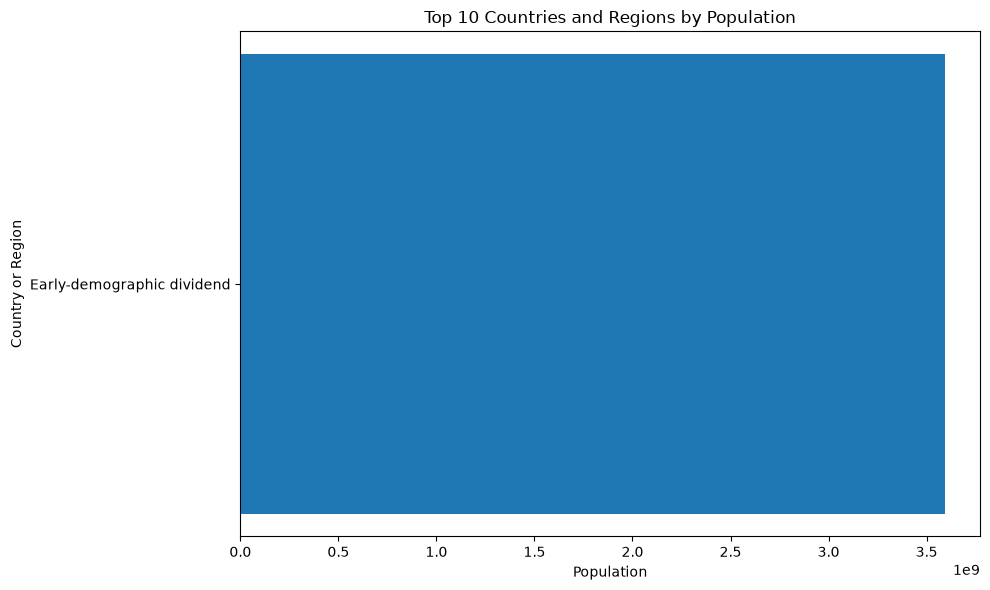

In [15]:
import matplotlib.pyplot as plt

top10 = population_df.head(10).copy()

plt.figure(figsize=(10, 6))
plt.barh(top10["国名"], top10["人口"])

plt.xlabel("Population")
plt.ylabel("Country or Region")
plt.title("Top 10 Countries and Regions by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

,国名,人口
330,Early-demographic dividend,3592750579
331,Early-demographic dividend,3552306404
332,Early-demographic dividend,3511607650
333,Early-demographic dividend,3470644834
334,Early-demographic dividend,3432026092
335,Early-demographic dividend,3396051187
336,Early-demographic dividend,3355014793
337,Early-demographic dividend,3314245247
338,Early-demographic dividend,3274060446
339,Early-demographic dividend,3233033717


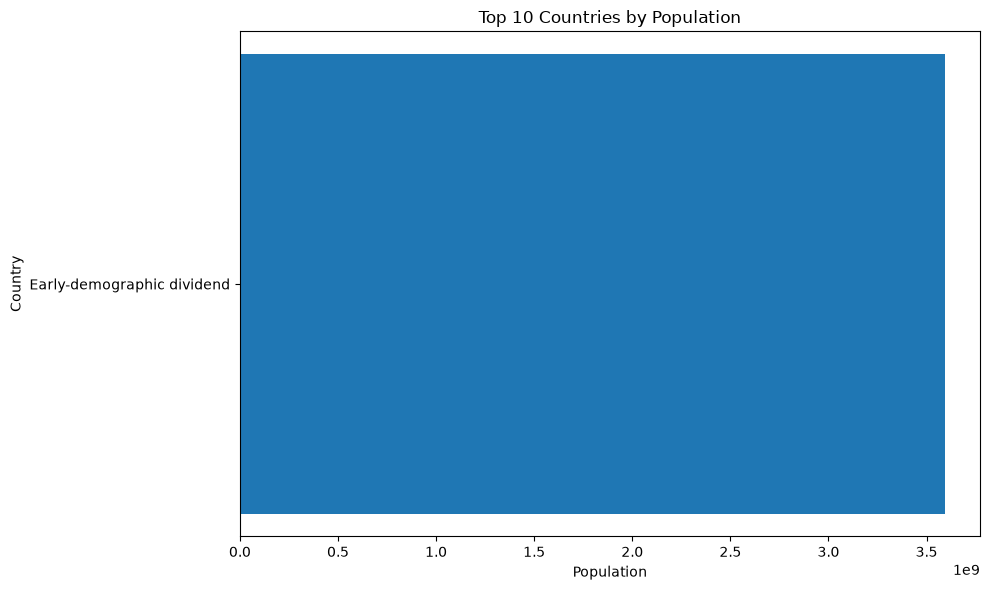

In [16]:
import matplotlib.pyplot as plt
import pandas as pd

# 世界銀行のデータから、国・地域の分類を除外する
countries = [
    item for item in result[1]
    if item["country"]["id"] not in ["", "WLD"]
    and item["value"] is not None
    and item["country"]["id"] != item["country"]["value"]
]

# 表を作成
population_df = pd.DataFrame([
    {
        "国名": item["country"]["value"],
        "人口": item["value"]
    }
    for item in countries
])

# 人口を数値に変換
population_df["人口"] = pd.to_numeric(
    population_df["人口"], errors="coerce"
)

# 人口の多い順に並べてトップ10を表示
population_df = population_df.dropna(subset=["人口"])
top10 = population_df.sort_values(
    "人口", ascending=False
).head(10)

display(top10)

# グラフを作成
plt.figure(figsize=(10, 6))
plt.barh(top10["国名"], top10["人口"])
plt.xlabel("Population")
plt.ylabel("Country")
plt.title("Top 10 Countries by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

,国名,人口
330,Early-demographic dividend,3592750579
331,Early-demographic dividend,3552306404
332,Early-demographic dividend,3511607650
333,Early-demographic dividend,3470644834
334,Early-demographic dividend,3432026092
335,Early-demographic dividend,3396051187
336,Early-demographic dividend,3355014793
337,Early-demographic dividend,3314245247
338,Early-demographic dividend,3274060446
339,Early-demographic dividend,3233033717


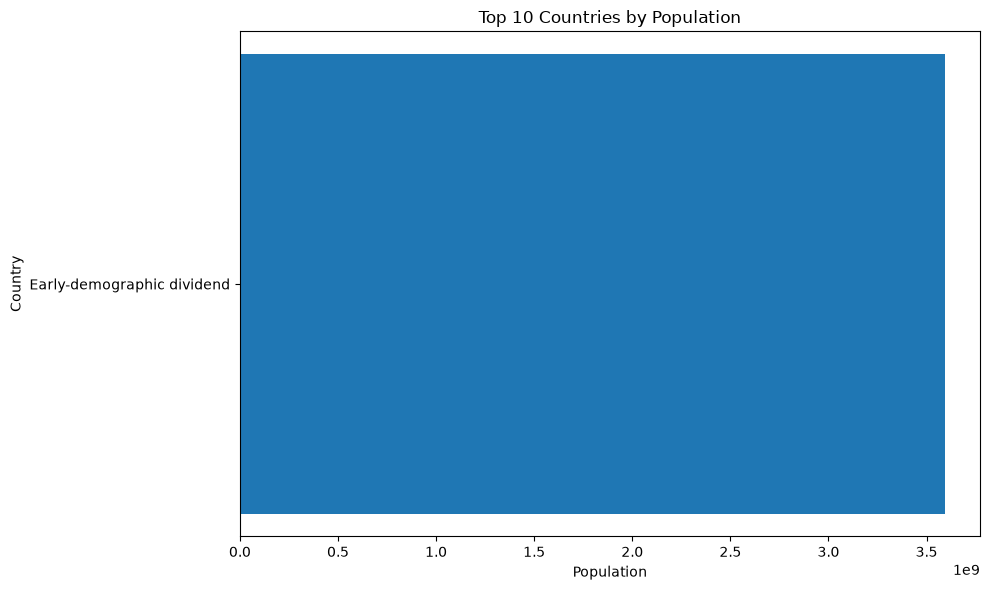

In [17]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# 世界銀行から国・地域の一覧を取得
countries_url = "https://api.worldbank.org/v2/country?format=json&per_page=400"
countries_response = requests.get(countries_url, timeout=30)
countries_response.raise_for_status()
countries_data = countries_response.json()[1]

# 国として扱われるデータのコードだけを取り出す
country_codes = {
    c["id"]: c["name"]
    for c in countries_data
    if c["region"]["id"] != ""
}

# 人口データを取得
population_url = (
    "https://api.worldbank.org/v2/country/all/indicator/"
    "SP.POP.TOTL?format=json&mrv=1&per_page=400"
)
population_response = requests.get(population_url, timeout=30)
population_response.raise_for_status()
population_data = population_response.json()[1]

# 国のデータだけに絞る
rows = []
for item in population_data:
    code = item["countryiso3code"]
    population = item["value"]

    if code in country_codes and population is not None:
        rows.append({
            "国名": country_codes[code],
            "人口": population
        })

# 人口ランキングを作成
population_df = pd.DataFrame(rows)
population_df = population_df.sort_values(
    "人口", ascending=False
)

top10 = population_df.head(10)

display(top10)

# グラフを作成
plt.figure(figsize=(10, 6))
plt.barh(top10["国名"], top10["人口"])
plt.xlabel("Population")
plt.ylabel("Country")
plt.title("Top 10 Countries by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
print("人口データの先頭5件")
print(population_df.head())

print("\n人口データの列名")
print(population_df.columns.tolist())

print("\nデータ件数")
print(len(population_df))

人口データの先頭5件
                             国名          人口
330  Early-demographic dividend  3592750579
331  Early-demographic dividend  3552306404
332  Early-demographic dividend  3511607650
333  Early-demographic dividend  3470644834
334  Early-demographic dividend  3432026092

人口データの列名
['国名', '人口']

データ件数
400


,国名,人口
43,World,8215424893
17,IDA & IBRD total,6993790788
26,Low & middle income,6791684991
30,Middle income,6024194822
16,IBRD only,5006926951
5,Early-demographic dividend,3592750579
6,East Asia & Pacific,2390873921
21,Late-demographic dividend,2330425681
7,East Asia & Pacific (excluding high income),2143908411
8,East Asia & Pacific (IDA & IBRD countries),2117367063


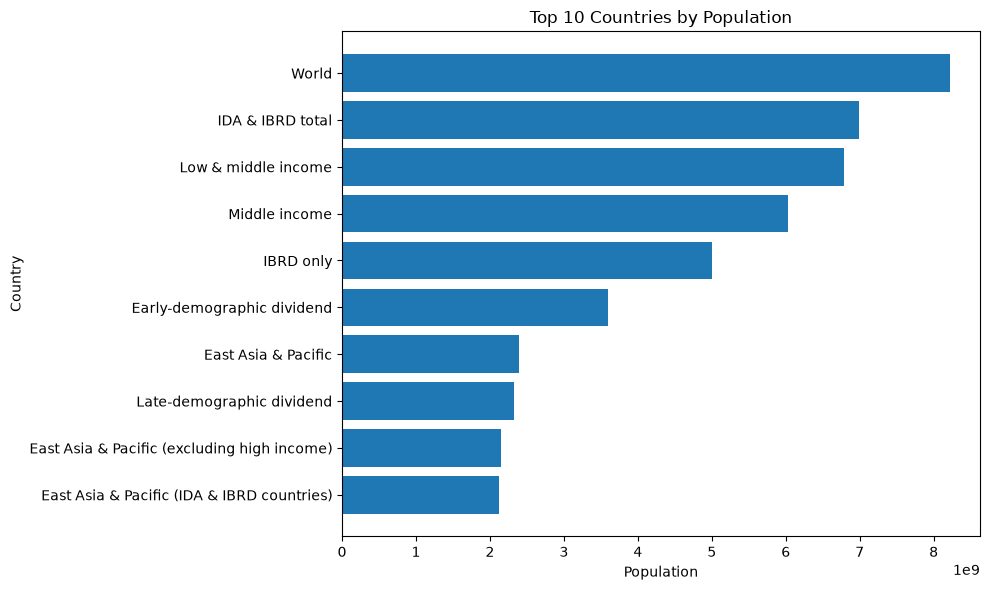

In [21]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# 世界銀行から国・地域の一覧を取得
url_countries = "https://api.worldbank.org/v2/country?format=json&per_page=400"
r_countries = requests.get(url_countries, timeout=30)
r_countries.raise_for_status()

country_data = r_countries.json()[1]

# 国のコードと名前を辞書にする
country_dict = {
    c["id"]: c["name"]
    for c in country_data
    if c["region"]["id"] != ""
}

# 人口データを取得
url_population = (
    "https://api.worldbank.org/v2/country/all/indicator/"
    "SP.POP.TOTL?format=json&mrnev=1&per_page=400"
)
r_population = requests.get(url_population, timeout=30)
r_population.raise_for_status()

population_data = r_population.json()[1]

# 国のコードと人口を組み合わせる
rows = []

for item in population_data:
    code = item.get("countryiso3code")
    population = item.get("value")

    if code in country_dict and population is not None:
        rows.append({
            "国名": country_dict[code],
            "人口": population
        })

# 人口ランキングを作成
population_df = pd.DataFrame(rows)
population_df = population_df.drop_duplicates(subset=["国名"])
population_df["人口"] = pd.to_numeric(
    population_df["人口"], errors="coerce"
)
population_df = population_df.dropna(subset=["人口"])
population_df = population_df.sort_values(
    "人口", ascending=False
).head(10)

# 表を表示
display(population_df)

# グラフを表示
plt.figure(figsize=(10, 6))
plt.barh(population_df["国名"], population_df["人口"])
plt.xlabel("Population")
plt.ylabel("Country")
plt.title("Top 10 Countries by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

,国名,人口
86,India,1463865525
40,China,1406585000
201,United States,341784857
87,Indonesia,285721236
144,Pakistan,255219554
139,Nigeria,237527782
26,Brazil,212812405
15,Bangladesh,175686899
156,Russian Federation,143513328
63,Ethiopia,135472051


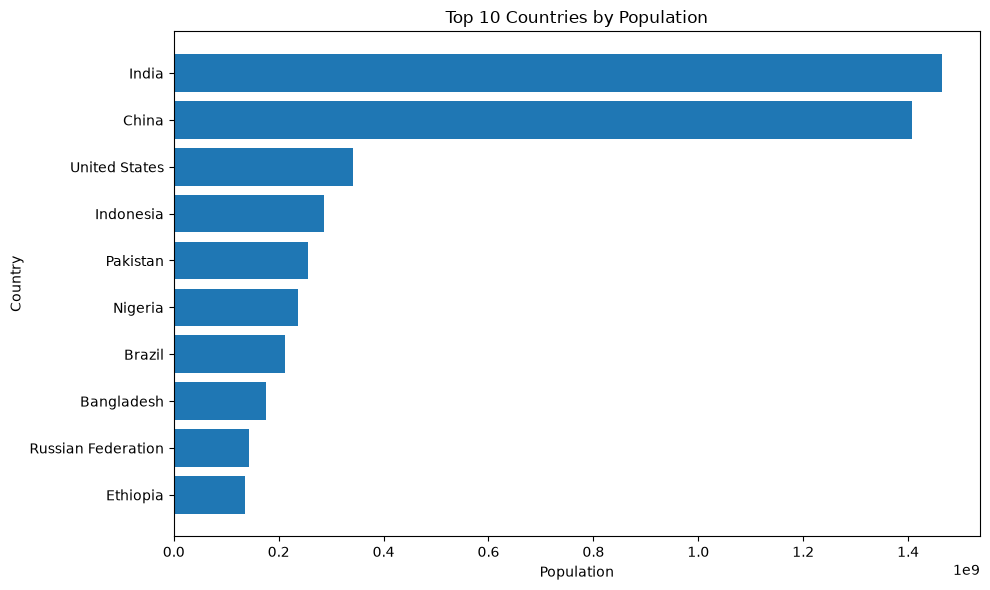

In [22]:
# 国の一覧から、地域分類を除外する
url = "https://api.worldbank.org/v2/country?format=json&per_page=400"
response = requests.get(url, timeout=30)
response.raise_for_status()

country_list = response.json()[1]

# 地域IDが空欄のものは集計地域なので除外する
valid_codes = {
    c["id"]: c["name"]
    for c in country_list
    if c["region"]["id"] != ""
    and c["capitalCity"] != ""
}

# 人口データを国コードで絞り込む
rows = []

for item in population_data:
    code = item.get("countryiso3code")
    population = item.get("value")

    if code in valid_codes and population is not None:
        rows.append({
            "国名": valid_codes[code],
            "人口": population
        })

# 人口ランキングを作成
population_df = pd.DataFrame(rows)
population_df = population_df.drop_duplicates(subset=["国名"])
population_df["人口"] = pd.to_numeric(
    population_df["人口"], errors="coerce"
)
population_df = population_df.dropna(subset=["人口"])
population_df = population_df.sort_values(
    "人口", ascending=False
)

# 上位10か国を表示
top10 = population_df.head(10)
display(top10)

# グラフを作成
plt.figure(figsize=(10, 6))
plt.barh(top10["国名"], top10["人口"])
plt.xlabel("Population")
plt.ylabel("Country")
plt.title("Top 10 Countries by Population")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

インドと中国が群を抜いて、人口が多いことが分かった。またインドネシアやパキスタンといった他のアジアの人口も増えてきている。と分かった。
どこの国籍を持っている人が住んでいるのかわからない。
出典：World Bank — Population, total　https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&mrv=1&per_page=400&utm_source=chatgpt.com
データの取得、グラフの作成、エラーの解決方法に対してAIを利用した。